In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.optimize import minimize
import scipy.stats as stats
import matplotlib.pyplot as plt
 

In [2]:
# Chargement des données
df = pd.read_excel('Test.xlsx', sheet_name=0)
df['Date'] = pd.to_datetime(df['Name'])
df = df.set_index('Date')
print(df.head())

# Sélection et renommage
prices = df[['BEL-DS', 'US-DS', 'USD-BIT']].copy()
prices.columns = ['Bel', 'US', 'BTC']
print(prices.head())

# Conversion en numérique et calcul des rendements logs
for col in prices.columns:
    prices[col] = pd.to_numeric(prices[col], errors='coerce')

returns = np.log(prices) - np.log(prices.shift(1))
print(returns.head())

In [3]:
#Coefficients extraits de WinRats
#Modèle r1m
b0_1 = 0.00045986
b1_1 = -0.0560
b2_1 = 0.2917

#Modèle r2m
b0_2 = 0.00056981
b1_2 = 0.0242
b2_2 = -0.0297

#Matrice C 
c11 = 0.0000016432
c12 = 0.00000042252
c22 = 0.0000015346

#Matrice A
a11 = 0.0502
a22 = 0.0397
a33 = 0.0681

#Matrice B
b11 = 0.9365
b22 = 0.9441
b33 = 0.9155

In [4]:
#--- 4. Boucle sur l'ensemble des données ---
# Préparation des données
data_loop = returns[['Bel', 'US']].dropna()
T = len(data_loop)
r1 = data_loop['Bel'].values
r2 = data_loop['US'].values

# Initialisation des vecteurs pour stocker les résultats
r1m = np.zeros(T)
r2m = np.zeros(T)
eps1 = np.zeros(T)
eps2 = np.zeros(T)
eps1_2 = np.zeros(T)
eps2_2 = np.zeros(T)
eps_cross = np.zeros(T)

eps1[0] = r1[0]
eps2[0] = r2[0]
eps_cross[0] = eps1[0] * eps2[0]

for t in range(1, T):
    r1m[t] = b0_1 + b1_1* r1[t-1] + b2_1 * r2[t-1]
    r2m[t] = b0_2 + b1_2 * r1[t-1] + b2_2 * r2[t-1]
    eps1[t] = r1[t] - r1m[t]
    eps2[t] = r2[t] - r2m[t]
    eps1_2[t] = eps1[t] * eps1[t]
    eps2_2[t] = eps2[t] * eps2[t]
    eps_cross[t] = eps1[t] * eps2[t]

# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_eps = pd.DataFrame({'eps1': eps1, 'eps2': eps2}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '1990-01-03'
date_end = '2021-07-23'

subset = df_eps.loc[date_start:date_end]

# Création des variables demandées
eps1_col = subset['eps1'].values
eps2_col = subset['eps2'].values

# Initialisation des vecteurs de variance pour stocker les résultats
h11_t = np.zeros(T)
h12_t = np.zeros(T)
h22_t = np.zeros(T)

# Valeurs initiales (Variance inconditionnelle empirique)  t=1  
h11_t[0] = np.var(eps1_col)
h12_t[0] = np.cov(eps1_col, eps2_col)[0, 1]
h22_t[0] = np.var(eps2_col)


print(h11_t[0], h12_t[0], h22_t[0])

#Calcul valeur t=2
h11_t[1] = c11 + a11*eps1[0]**2 + b11*h11_t[0]
h12_t[1] = c12 + a22*eps_cross[0] + b22*h12_t[0]
h22_t[1] = c22 + a33*eps2[0]**2 + b33*h22_t[0]


#Calcul valeur t=3 to T
for t in range(2, T): 
    h11_t[t] = c11 + a11*eps1[t-1]**2 + b11*h11_t[t-1]
    h12_t[t] = c12 + a22*eps_cross[t-1] + b22*h12_t[t-1]
    h22_t[t] = c22 + a33*eps2[t-1]**2 + b33*h22_t[t-1]



0.00011974583778044642 5.6859388116993634e-05 0.0001223910730293342


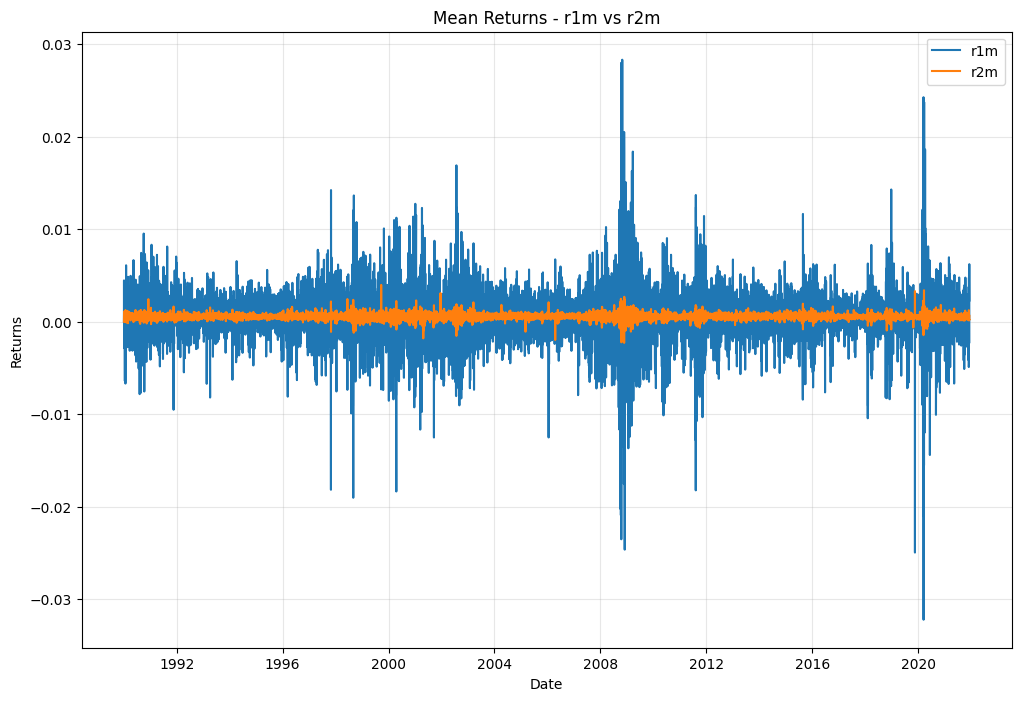

In [5]:
plt.figure(figsize=(12, 8))
plt.plot(data_loop.index, r1m, label='r1m', lw=1.5)
plt.plot(data_loop.index, r2m, label='r2m', lw=1.5)
plt.legend()
plt.grid(alpha=0.3)
plt.title('Mean Returns - r1m vs r2m')
plt.xlabel('Date')
plt.ylabel('Returns')
plt.show()

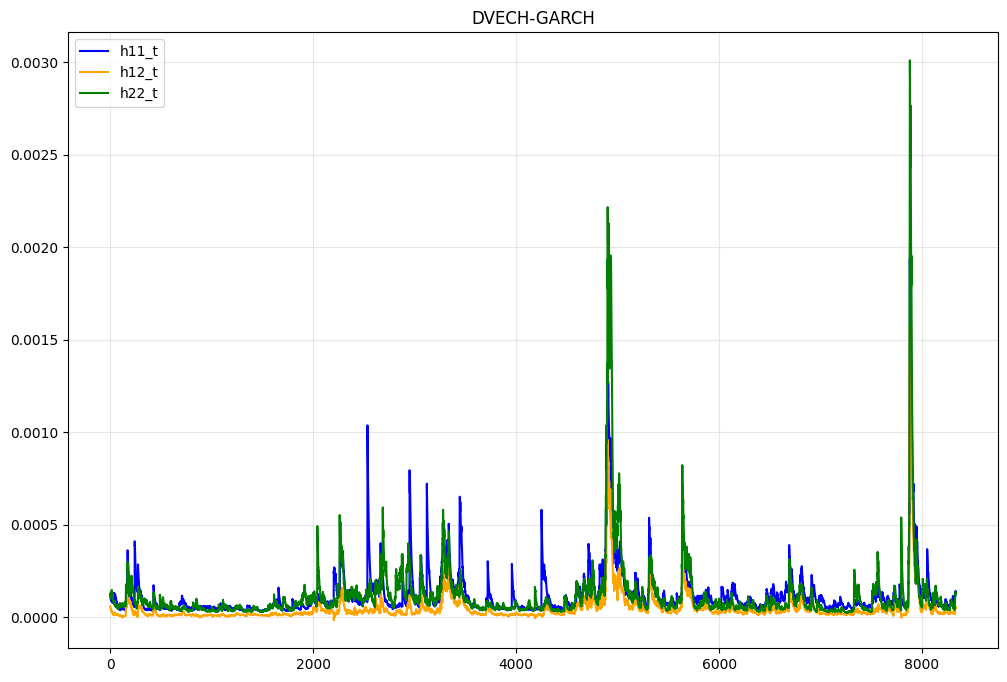

In [6]:
plt.figure(figsize=(12,8))
plt.plot(h11_t, 'b-', label='h11_t', lw=1.5)
plt.plot(h12_t, 'orange', label='h12_t', lw=1.5)
plt.plot(h22_t, 'g-', label='h22_t', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('DVECH-GARCH'); plt.show()


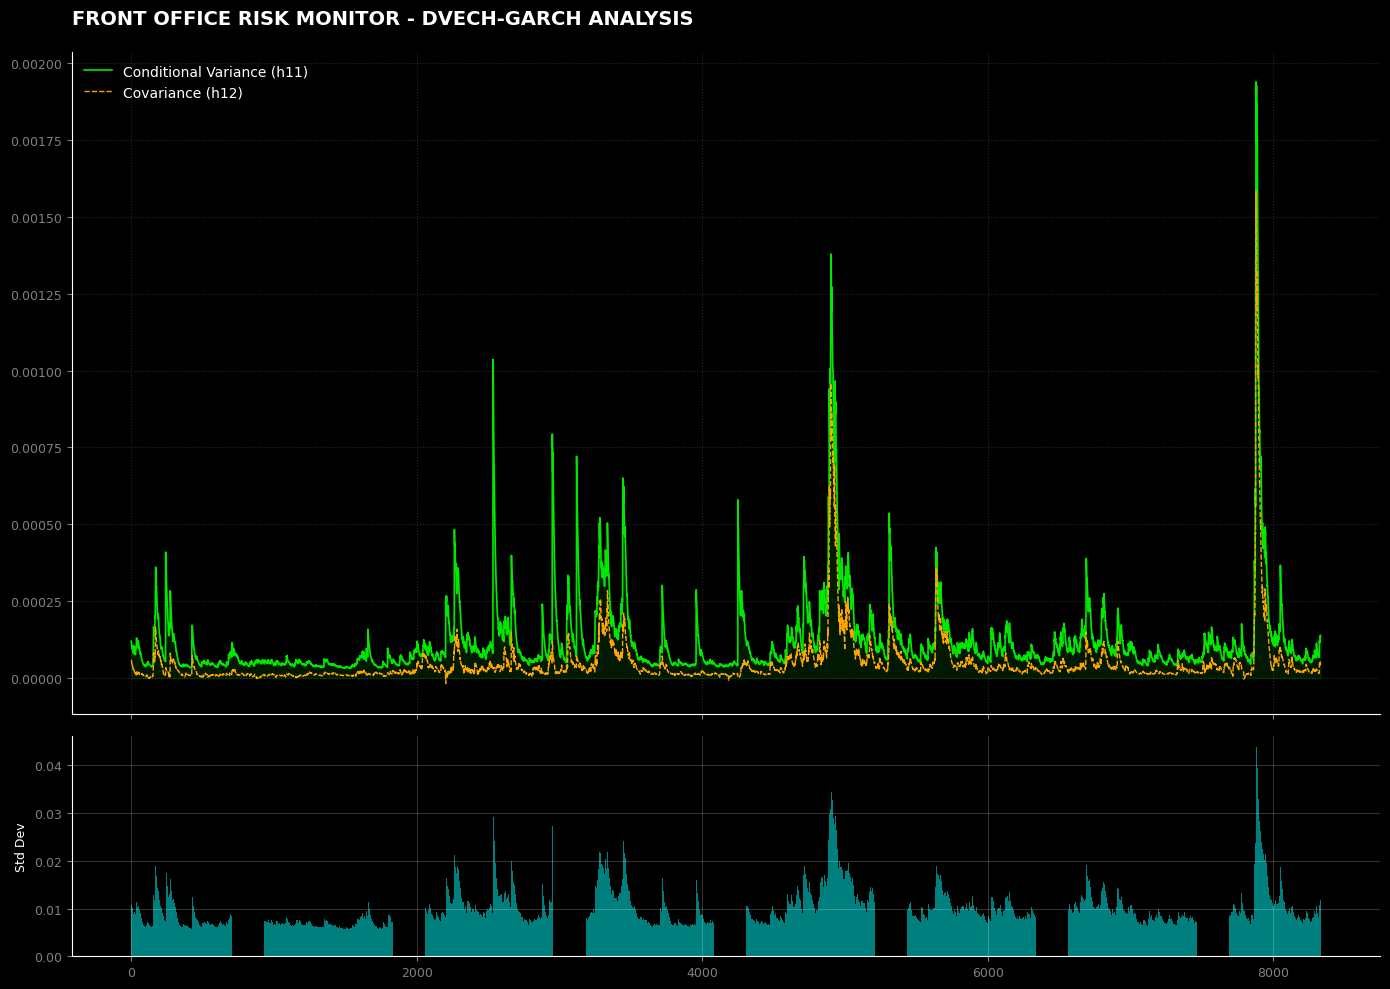

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# On définit un style sombre et pro
plt.style.use('dark_background')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, 
                               gridspec_kw={'height_ratios': [3, 1]})

# --- GRAPHIQUE SUPÉRIEUR : VaR & RENDEMENTS ---
# On trace tes composantes de variance (ex: h11_t qui est la variance de l'actif 1)
# Pour une VaR, on prend souvent la racine carrée (volatilité)
ax1.plot(h11_t, color='#00FF00', lw=1.2, label='Conditional Variance (h11)', alpha=0.9)
ax1.plot(h12_t, color='orange', lw=1, label='Covariance (h12)', linestyle='--')

# On ajoute un remplissage pour l'aspect "Risk Area"
ax1.fill_between(range(len(h11_t)), h11_t, color='#00FF00', alpha=0.1)

ax1.set_title('FRONT OFFICE RISK MONITOR - DVECH-GARCH ANALYSIS', 
              fontsize=14, fontweight='bold', color='white', loc='left', pad=20)
ax1.legend(loc='upper left', frameon=False)
ax1.grid(color='gray', linestyle=':', alpha=0.3)

# --- GRAPHIQUE INFÉRIEUR : INDICATEUR DE STRESS (Z-Score/Residuals) ---
# On utilise souvent les résidus standardisés pour voir si le modèle "tient"
# Si tu n'as pas 'residus', on peut simuler l'écart type
ax2.bar(range(len(h11_t)), np.sqrt(h11_t), color='cyan', alpha=0.5, label='Volatility Spike')
ax2.set_ylabel('Std Dev', fontsize=9)
ax2.grid(alpha=0.2)

# Finition "Terminal" : supprimer les bordures inutiles
for ax in [ax1, ax2]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', colors='gray', labelsize=9)

plt.tight_layout()
plt.subplots_adjust(hspace=0.05) # On colle les graphiques pour l'aspect dashboard
plt.show()

In [8]:
# Création d'un DataFrame pour aligner les résultats numpy avec l'index temporel original
df_Dvech = pd.DataFrame({'r1': r1, 'r1m': r1m, 'h11_t': h11_t}, index=data_loop.index)

# Extraction des données sur la plage de dates spécifiée
date_start = '2021-07-23'
date_end = '2021-12-09'

subset = df_Dvech.loc[date_start:date_end]

# Création des variables demandées
n_subset = len(subset)
r1_new = subset['r1'].values
r1m_new = subset['r1m'].values
h11_t_new = subset['h11_t'].values

VaR = np.zeros(n_subset)
Val_V = np.zeros(n_subset)
Perte = np.zeros(n_subset)


Val_V[0] = 100000 * (1 + r1_new[0])
Val_V[1] = Val_V[0] * (1 + r1_new[1])
Perte[0] = 100000 - Val_V[0]
Perte[1] = Val_V[0] - Val_V[1]

for t in range(2, n_subset):
    Val_V[t] = Val_V[t-1] * (1 + r1_new[t])
    Perte[t] = Val_V[t-1] - Val_V[t]


VaR[0] = 100000 * ((-r1m_new[0] + 1.645 * (h11_t_new[0]**0.5)))
for t in range(1, n_subset):
    VaR[t] = Val_V[t-1]*((-r1m_new[t]+ 1.645*(h11_t_new[t]**0.5)))

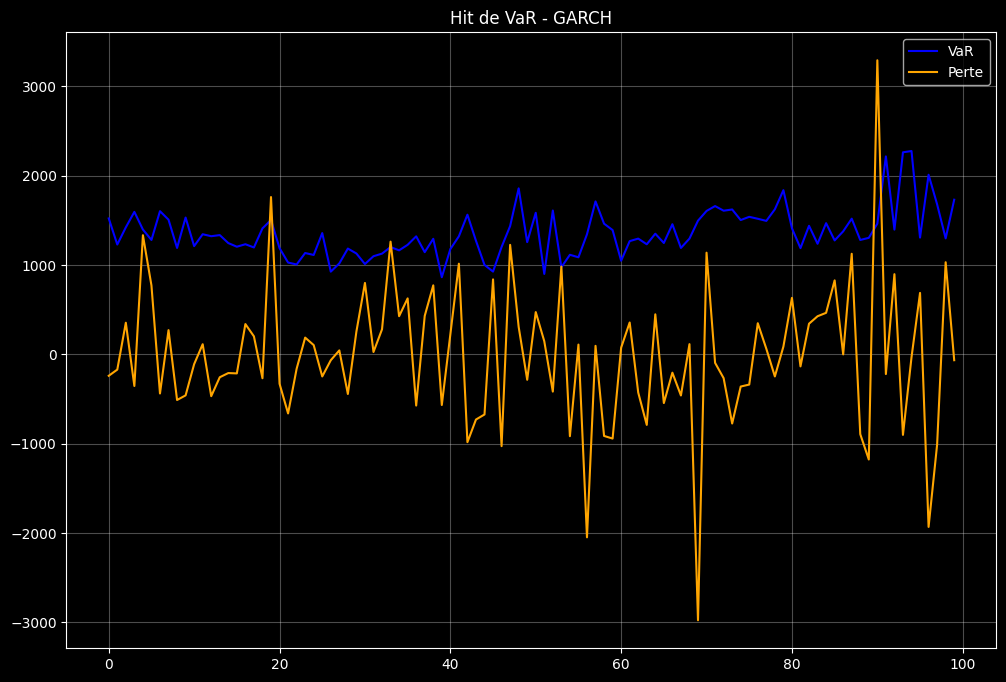

In [9]:
plt.figure(figsize=(12,8))
plt.plot(VaR, 'b-', label='VaR', lw=1.5)
plt.plot(Perte, 'orange', label='Perte', lw=1.5)
plt.legend(); plt.grid(alpha=0.3); plt.title('Hit de VaR - GARCH'); plt.show()

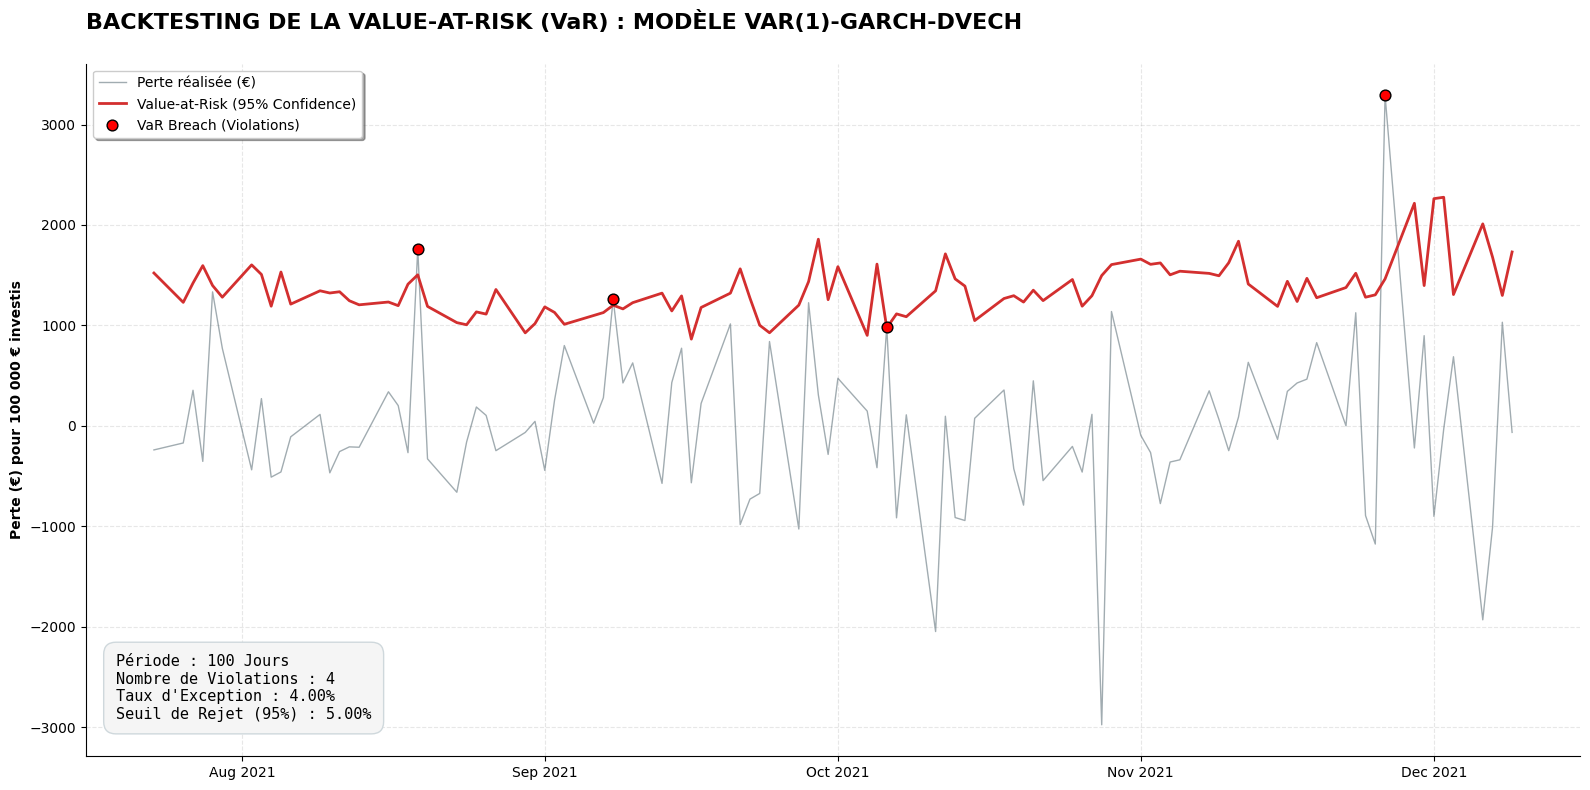

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# --- 1. SYNCHRONISATION DES DIMENSIONS ---
# On s'assure que l'index correspond à la taille de vos prévisions (les 100 dernières observations)
plot_index = data_loop.index[-len(Perte):]

# --- 2. CONFIGURATION DU STYLE "RISK AUDIT" ---
plt.style.use('default')
fig, ax = plt.subplots(figsize=(16, 8), facecolor='white')
ax.set_facecolor('white')

# 3. IDENTIFICATION DES VIOLATIONS (BREACHES)
# Une violation se produit quand la perte réalisée dépasse la VaR
hits = Perte > VaR 

# 4. TRACÉ DES SÉRIES (HIÉRARCHIE VISUELLE)
# Rendements réels en bleu acier (discret pour laisser la priorité aux alertes)
ax.plot(plot_index, Perte, color='#455a64', lw=1, alpha=0.5, label='Perte réalisée (€)')

# VaR en rouge écarlate (Le signal de risque)
ax.plot(plot_index, VaR, color='#d32f2f', lw=2, label='Value-at-Risk (95% Confidence)', zorder=4)

# 5. MARQUAGE DES "HITS" (POINTS D'ALERTE)
# Marquage des dates de dépassement
ax.scatter(plot_index[hits], Perte[hits], color='red', s=60, 
           label='VaR Breach (Violations)', zorder=5, edgecolor='black', marker='o')

# 6. HABILLAGE FRONT OFFICE
ax.set_title('BACKTESTING DE LA VALUE-AT-RISK (VaR) : MODÈLE VAR(1)-GARCH-DVECH', 
             loc='left', fontsize=16, fontweight='bold', pad=25)
ax.set_ylabel('Perte (€) pour 100 000 € investis', fontweight='bold')

# --- 7. CARTOUCHE DE STATISTIQUES (L'AUDIT DU RISK MANAGER) ---
nb_hits = np.sum(hits)
tx_exception = (nb_hits / len(Perte)) * 100
stats_audit = (f"Période : {len(Perte)} Jours\n"
               f"Nombre de Violations : {nb_hits}\n"
               f"Taux d'Exception : {tx_exception:.2f}%\n"
               f"Seuil de Rejet (95%) : 5.00%")

ax.text(0.02, 0.05, stats_audit, transform=ax.transAxes, fontsize=11, family='monospace',
        verticalalignment='bottom', bbox=dict(boxstyle='round,pad=0.8', facecolor='#f5f5f5', edgecolor='#cfd8dc'))

# Formatage des axes
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper left', frameon=True, shadow=True, fontsize=10)

# Nettoyage visuel
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series, name):
    result = adfuller(series.dropna())
    print(f"--- Test ADF pour {name} ---")
    print(f"Statistique : {result[0]:.4f}")
    print(f"p-value : {result[1]:.4f}")
    print("----------------------------")

# Test sur les rendements
check_stationarity(returns['Bel'], "marché belge")
check_stationarity(returns['US'], "marché américain")

/tmp/ipykernel_158/3740657936.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


--- Test ADF pour marché belge ---
Statistique : -24.4930
p-value : 0.0000
----------------------------


--- Test ADF pour marché américain ---
Statistique : -16.1538
p-value : 0.0000
----------------------------


/tmp/ipykernel_158/3740657936.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


In [12]:
# Test de Kupiec (proportion de violations, POF) : le taux observé est-il compatible avec 5 % ?
from scipy.stats import chi2, binom

def kupiec_pof(nb_violations, n, p=0.05):
    """Statistique du rapport de vraisemblance de Kupiec et sa p-value (loi du khi-deux à 1 degré de liberté)."""
    x, pi = nb_violations, nb_violations / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - pi) + (x * np.log(pi) if x > 0 else 0.0)
    lr = -2 * (ll0 - ll1)
    return lr, 1 - chi2.cdf(lr, 1)

n_obs, x_obs = len(Perte), int(np.sum(Perte > VaR))
lr, pval = kupiec_pof(x_obs, n_obs, p=0.05)
bas, haut = int(binom.ppf(0.025, n_obs, 0.05)), int(binom.ppf(0.975, n_obs, 0.05))
print(f"Violations : {x_obs} sur {n_obs} jours (attendu : {0.05 * n_obs:.0f})")
print(f"Kupiec LR = {lr:.3f}, p-value = {pval:.3f} -> " + ("modèle non rejeté à 5 %" if pval > 0.05 else "modèle rejeté à 5 %"))
print(f"Zone d'acceptation à 95 % : de {bas} à {haut} violations")


Violations : 4 sur 100 jours (attendu : 5)
Kupiec LR = 0.225, p-value = 0.635 -> modèle non rejeté à 5 %
Zone d'acceptation à 95 % : de 1 à 10 violations
